## Model Experiment

In [24]:

import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Support running from either notebooks/ or the project root
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

sys.path.insert(0, str(root))

from src.preprocessing import create_preprocessor
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay)

In [25]:
pipeline = Pipeline(
    [
        ("preprocessing",create_preprocessor()),
        ("model",LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state = 42
        ))
    ]
)

In [26]:
train = pd.read_csv("../data/processed/train.csv")

X_train = train.drop(columns = ["Class"])
y_train = train["Class"]

In [27]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scale', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

In [29]:
val = pd.read_csv("../data/processed/val.csv")
X_val = val.drop(columns = ["Class"])
y_val = val["Class"]

In [30]:
validation = pipeline.predict(X_val)

In [31]:
print("Classification Report")
print("\n ", classification_report(validation, y_val))

Classification Report

                precision    recall  f1-score   support

           0       0.97      1.00      0.99     55216
           1       0.91      0.05      0.10      1529

    accuracy                           0.97     56745
   macro avg       0.94      0.53      0.55     56745
weighted avg       0.97      0.97      0.96     56745



Confusion Matrix

 [[55208  1445]
 [    8    84]]


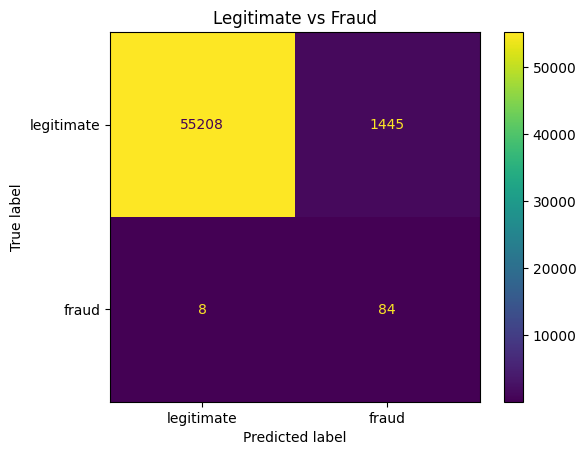

In [32]:
cm = confusion_matrix(y_val, validation)
print("Confusion Matrix")
print("\n", cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix= cm,
    display_labels=["legitimate", "fraud"]
)

disp.plot()
plt.title("Legitimate vs Fraud")
plt.show()